# Simulate a cohort

In this tutorial we grow a small cohort of patients over one configuration with [`Cohort`](https://pedrofale.github.io/iscc/reference/Cohort/), generate scRNA for each patient, pool the patients into sequencing batches and read the ground truth across patients.
The patients share the layout seed, which draws the driver genes and the baseline expression of each cell type.
Each patient has its own evolution seed, which draws the gland field, the clones, the mutations and the spatial history of the patient.
The tool tutorial on [batch integration](tool_integration.ipynb) builds on such a cohort.
The notebook runs in under a minute on a laptop.

In [1]:
import os
import warnings
os.environ["KMP_WARNINGS"] = "0"  # silence a deprecation notice of OpenMP in the UMAP dependencies
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="numba")
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

from iscc.cohort import Cohort, clone_key, concat_cohort_batches, recurrence_table, run_cohort_batches, shared_private_labels
from iscc.integrations import biological_types, clones_from_clades
from iscc.sample import Resection
from iscc.tumor import GenotypeTumor

## Grow the cohort

`Cohort` calls a growth function once per patient, with the evolution seed of the patient and the shared layout seed.
Our growth function builds the tumor of `tutorial_config.yaml`, as in the [Quickstart](01_quickstart.ipynb), and grows it to 6,000 cancer cells, a small tumor in situ that has spread from its founding gland to the other glands.

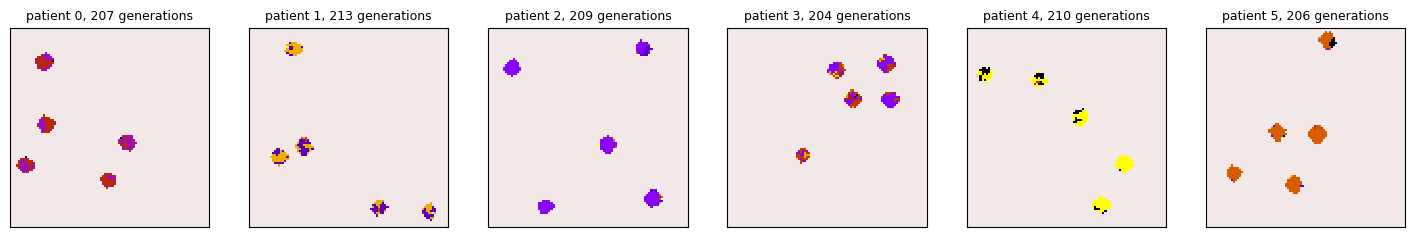

In [2]:
def grow(seed, layout_seed):
    tumor = GenotypeTumor(config="tutorial_config.yaml", seed=seed, layout_seed=layout_seed)
    tumor.grow(n_steps=1000, target_cancer=6000, materialize=False)
    return tumor


cohort = Cohort(grow, patient_seeds=[11, 12, 13, 14, 15, 16]).run()

fig, axes = plt.subplots(1, cohort.n_patients, figsize=(3 * cohort.n_patients, 3))
for ax, patient in zip(axes, cohort.patients):
    patient.tumor.plot_tissue(ax=ax, color="clone", min_freq=0.01)
    ax.set_title(f"patient {patient.patient_id}, {patient.tumor.time:.0f} generations", fontsize=9)
plt.show()

Every patient reached 6,000 cancer cells after 204 to 213 generations, with cancer cells in all five glands, and one or two driver clones dominate each patient.

## Sample each patient

We resect a window of 20 by 20 demes, about 1 mm across, centered on the founding gland of each patient, and dissociate it into a sample of 3,000 cells with a [`Resection`](https://pedrofale.github.io/iscc/reference/Resection/).
With `install=True` the sample becomes the cell table of the patient, which the cohort functions below read.
We then label the cancer cells of each patient with clones, which are clades of the true genealogy with at least 30 sampled cells ([`clones_from_clades`](https://pedrofale.github.io/iscc/reference/clones_from_clades/)).

In [3]:
clone = {}
for patient in cohort.patients:
    tumor = patient.tumor
    region = tumor.primary_window(side=20, center=tumor.gland_centers[0])
    sample = Resection(tumor).dissociate(region=region, max_cells=3000, install=True, layers="scrna", seed=patient.seed)
    labels = clones_from_clades(tumor, min_cells=30)
    clone.update({clone_key(patient.patient_id, cell): f"P{patient.patient_id} {label}"
                  for cell, label in labels.dropna().items()})
    types = pd.Series(biological_types(sample["cell_type"]["cell_id"])).value_counts()
    print(f"patient {patient.patient_id}: {types.to_dict()}, {labels.cat.categories.size} clone labels")

patient 0: {'stromal': 1127, 'immune': 748, 'cancer': 736, 'epithelial': 440}, 2 clone labels


patient 1: {'stromal': 996, 'cancer': 797, 'immune': 694, 'epithelial': 562}, 4 clone labels


patient 2: {'stromal': 1061, 'immune': 768, 'cancer': 709, 'epithelial': 422}, 4 clone labels


patient 3: {'stromal': 1135, 'immune': 736, 'cancer': 731, 'epithelial': 421}, 4 clone labels


patient 4: {'stromal': 1130, 'immune': 706, 'cancer': 691, 'epithelial': 418}, 4 clone labels


patient 5: {'stromal': 1127, 'immune': 769, 'cancer': 729, 'epithelial': 434}, 3 clone labels


Each sample contains 691 to 797 cancer cells, 996 to 1,135 stromal cells, 694 to 769 immune cells and 418 to 562 epithelial cells, and the clone labels of a patient include `other` for the cancer cells outside every clade.

## Pool the patients into sequencing batches

`run_cohort_batches` draws scRNA for 500 cells of each patient and assigns the patients to sequencing batches, where each batch is one realization of the technical noise of [`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/).
With `mapping="one_to_one"` each patient is sequenced in its own batch, so that batch and patient are confounded.
With `mapping="multiplex"` and `capacity=3`, three patients share each batch, as in a design with cell hashing or genetic demultiplexing, so that each batch contains cells of several patients.
`concat_cohort_batches` joins the batches into one AnnData with the patient and the batch of each cell.

In [4]:
designs = {}
for mapping, capacity in (("one_to_one", None), ("multiplex", 3)):
    assays, batches, assignment = run_cohort_batches(cohort, mapping=mapping, capacity=capacity, n_cells_per_patient=500)
    adata = concat_cohort_batches(assays)
    cell = adata.obs_names.str.rsplit("-", n=1).str[0]
    adata.obs["patient"] = adata.obs["patient"].astype(str)
    adata.obs["cell_type"] = biological_types(adata.obs["clone"])
    adata.obs["clone"] = cell.map(clone).values
    designs[mapping] = adata
    print(f"{mapping}: {adata.n_obs:,} cells, batches {batches}")

one_to_one: 3,000 cells, batches {0: [0], 1: [1], 2: [2], 3: [3], 4: [4], 5: [5]}


multiplex: 3,000 cells, batches {0: [0, 1, 2], 1: [3, 4, 5]}


We run the standard scanpy workflow on each design and color the cells by patient, batch and cell type, without any batch correction.

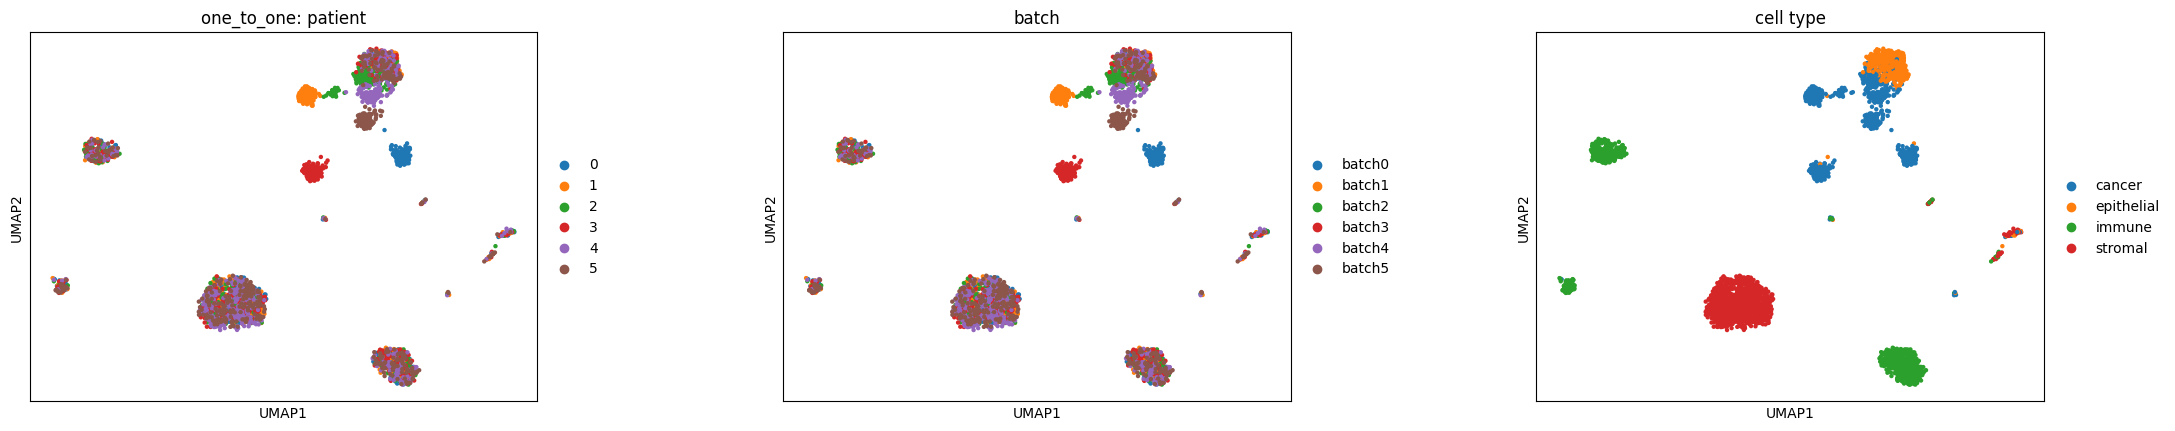

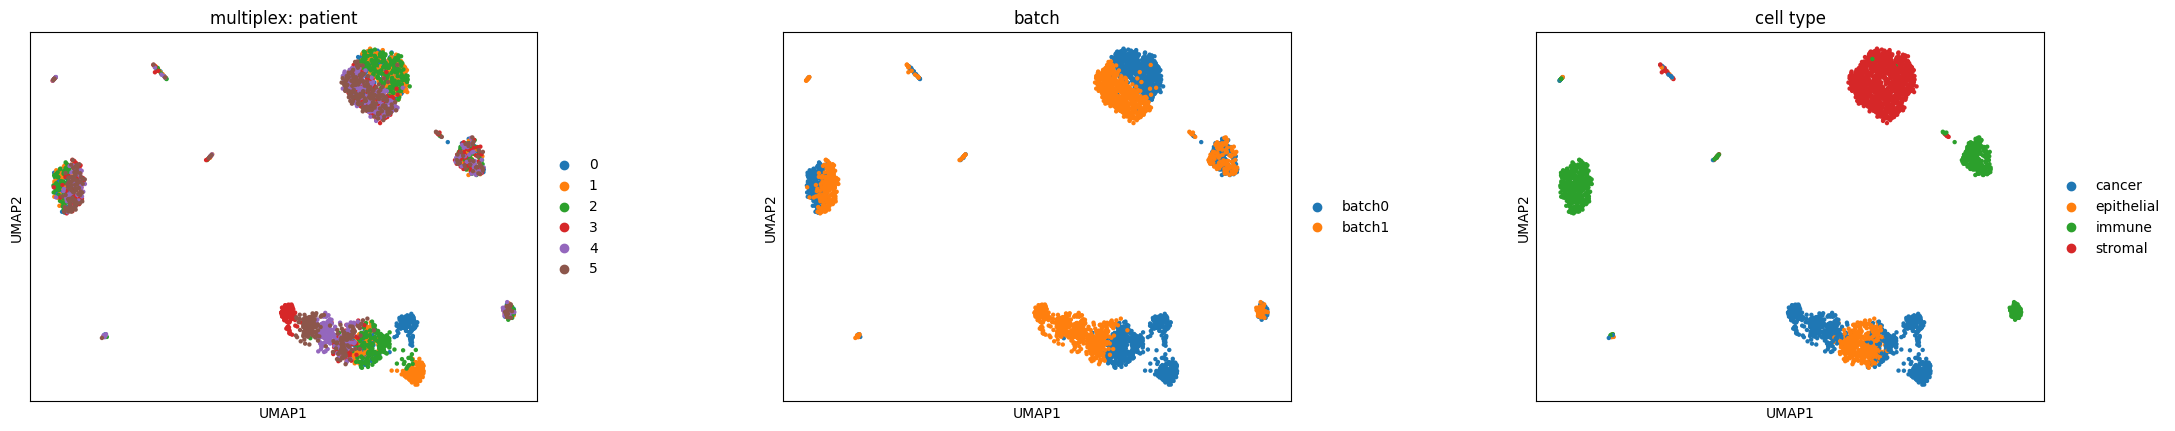

In [5]:
for mapping, adata in designs.items():
    adata.layers["counts"] = adata.X.copy()
    sc.pp.normalize_total(adata)
    sc.pp.log1p(adata)
    sc.pp.pca(adata)
    sc.pp.neighbors(adata)
    sc.tl.umap(adata)
    sc.pl.umap(adata, color=["patient", "batch", "cell_type"], wspace=0.35, title=[f"{mapping}: patient", "batch", "cell type"])

With one batch per patient, the stromal, immune and epithelial cells of all patients overlap, and the cancer cells form one cluster per patient, in which patient and batch cannot be told apart.
The immune cells form one cluster for each of their three subtypes.
With three patients per batch, the stromal, immune, epithelial and cancer cells split by batch, which is the batch effect an integration method should remove, while the cancer cells within a batch still separate by patient.

## Read the ground truth across patients

`shared_private_labels` gives each cell two labels.
The shared state is the cell type, which an integration method should align across patients, and the private state is the patient, which the method should keep apart.
The clone labels are private by construction, since each patient has its own genealogy.

In [6]:
adata = designs["multiplex"]
states = shared_private_labels(adata.obs)
print(pd.crosstab(states["shared_state"], states["private_state"]).to_string())
print(f"\n{adata.obs['clone'].nunique()} clone labels over {adata.obs['patient'].nunique()} patients")

private_state    0    1    2    3    4    5
shared_state                               
cancer         122  132  127  110  116  116
epithelial      84   90   68   67   71   69
immune         120  105  119  130  122  136
stromal        174  173  186  193  191  179

21 clone labels over 6 patients


`recurrence_table` gives for every gene the number of patients in which it is mutated in at least 5% of the cancer cells, together with the true role of the gene, which is the ground truth for the detection of recurrent drivers.

In [7]:
recurrence = recurrence_table(cohort)
print(pd.crosstab(recurrence["n_patients_mutated"], recurrence["is_driver"].map({True: "driver", False: "other gene"})).to_string())
recurrence[recurrence["is_driver"]].sort_values("n_patients_mutated", ascending=False).head(8)

is_driver           driver  other gene
n_patients_mutated                    
0                      201        5258
1                       33         490
2                        2          15
3                        0           1


,is_oncogene,is_tsg,n_patients_mutated,recurrence,is_driver,is_recurrent
gene,,,,,,
G_11_460,False,True,2,0.333333,True,True
G_1_497,False,True,2,0.333333,True,True
G_3_118,True,False,1,0.166667,True,False
G_9_389,True,False,1,0.166667,True,False
G_10_160,True,False,1,0.166667,True,False
G_1_325,False,True,1,0.166667,True,False
G_7_386,True,False,1,0.166667,True,False
G_3_410,False,True,1,0.166667,True,False


In this small cohort the driver genes are mutated only somewhat more often than the other genes, since 35 of the 236 drivers (15%) and 506 of the 5,764 other genes (9%) are mutated in at least one patient.
Two tumor suppressor genes are mutated in two patients each, against 15 other genes in two patients and one in three.
Recurrence therefore does not single out the drivers here, possibly because selection at a driver effect of 1.03 is weak, and a benchmark of driver detection may need more patients or a larger driver effect ([Shape the tumor](02_shape_the_tumor.ipynb)).

## Next steps

The patients here are small tumors that grow in seconds, to show the `Cohort` API.
For analyses that need realistic patients, `iscc.pregrown.cohort()` loads six patients grown once with the paper's regime to 60,000 cancer cells each ([pregrown tumors](https://pedrofale.github.io/iscc/reference/#pregrown-tumors)).
[Batch integration](tool_integration.ipynb) integrates the pooled scRNA of a cohort with Harmony and scVI.